In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [13]:
from google.colab import files
df = pd.read_csv('/content/diabetes.csv')

In [14]:
print(df.shape)
df.head()

(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [17]:
x = df.drop(columns=['Outcome'])
y = df['Outcome']

In [18]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

model = GaussianNB()
model.fit(x_train, y_train)

GaussianNB()

In [19]:
test = [[6, 148, 72, 35, 0, 33.6, 0.627, 50]]
test_df = pd.DataFrame(test, columns=x.columns)

print("\n----prediction-------------------------")
pred = model.predict(test_df)[0]
prob = model.predict_proba(test_df)[0]

print("Input:", dict(zip(x.columns, test[0])))
print("Result:Diabetes ->", "Yes" if pred == 1 else "No")
print(f"p(No)  ={prob[0]:.4f}")
print(f"p(Yes) ={prob[1]:.4f}")


----prediction-------------------------
Input: {'Pregnancies': 6, 'Glucose': 148, 'BloodPressure': 72, 'SkinThickness': 35, 'Insulin': 0, 'BMI': 33.6, 'DiabetesPedigreeFunction': 0.627, 'Age': 50}
Result:Diabetes -> Yes
p(No)  =0.2653
p(Yes) =0.7347


In [20]:
y_pred = model.predict(x_test)

print(f"Test Accuracy : {accuracy_score(y_test, y_pred)*100:.2f}%")
print(f"Train Accuracy: {accuracy_score(y_train, model.predict(x_train))*100:.2f}%")
print("\nClassification Report:\n", classification_report(y_test, y_pred))

Test Accuracy : 76.62%
Train Accuracy: 75.24%

Classification Report:
               precision    recall  f1-score   support

           0       0.83      0.80      0.81        99
           1       0.66      0.71      0.68        55

    accuracy                           0.77       154
   macro avg       0.75      0.75      0.75       154
weighted avg       0.77      0.77      0.77       154



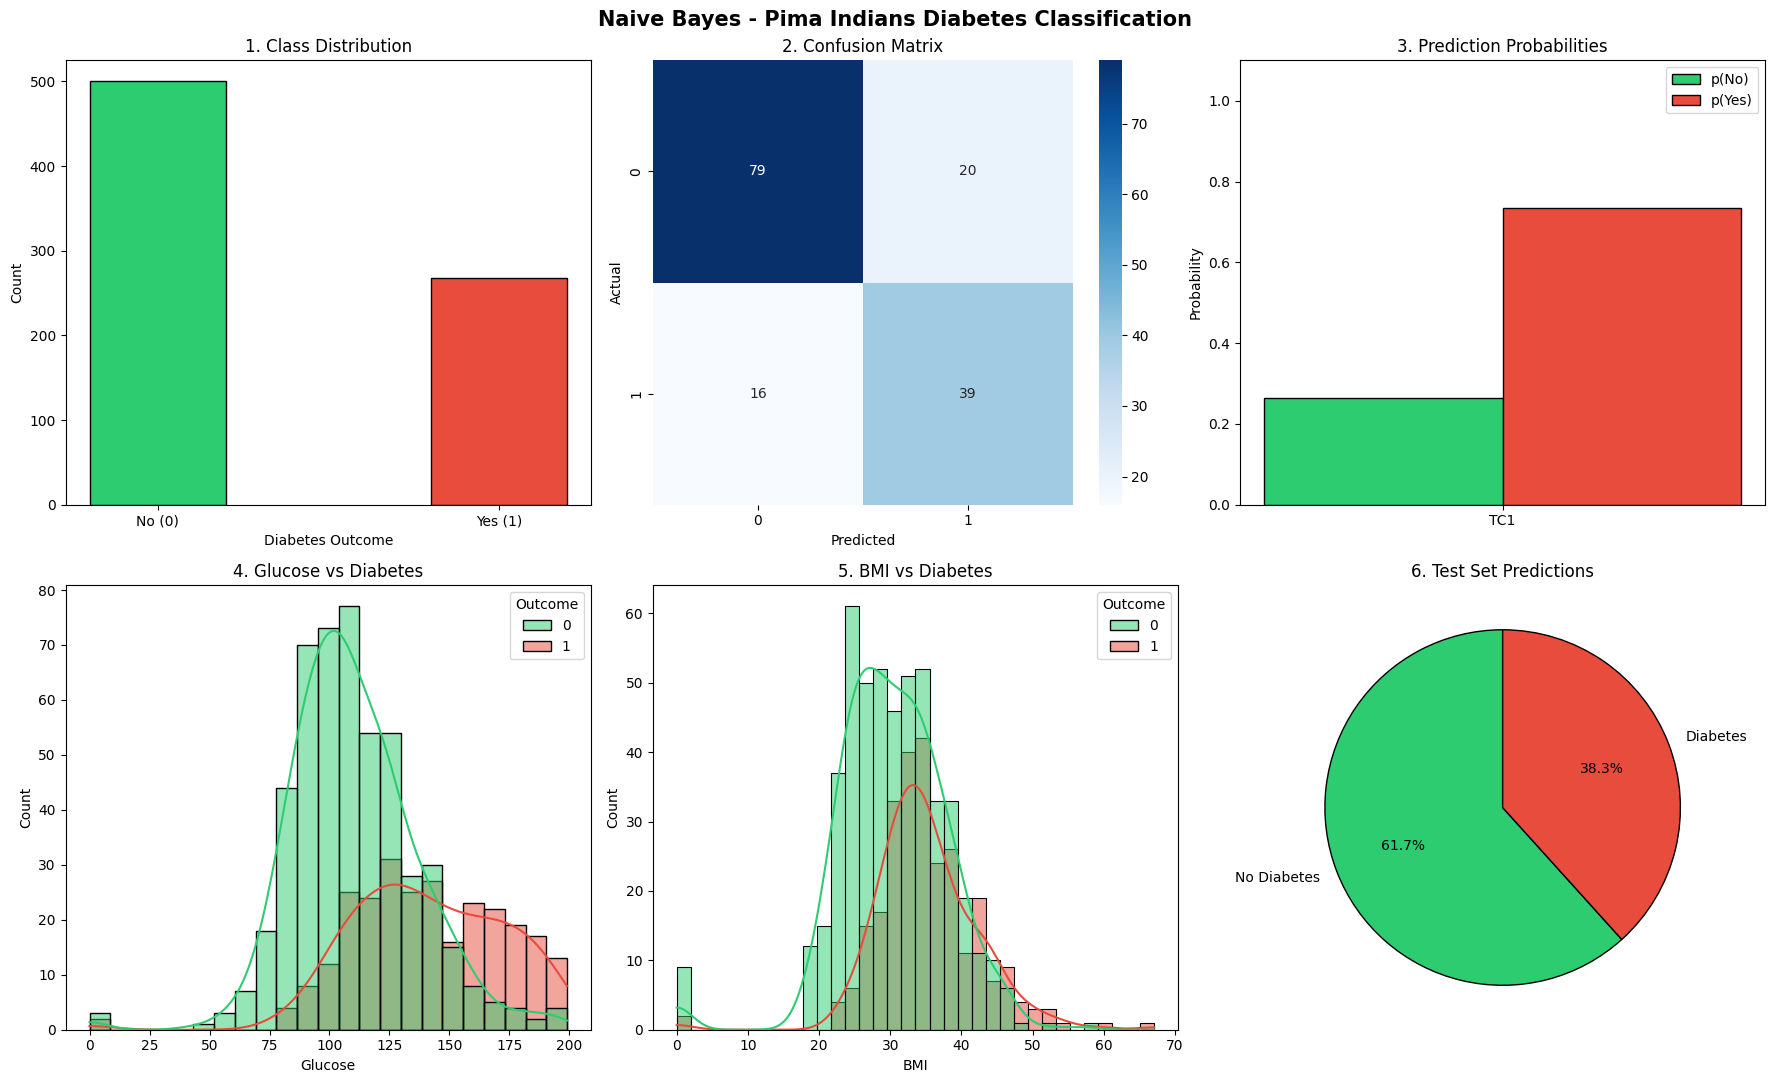

In [21]:
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
fig.suptitle("Naive Bayes - Pima Indians Diabetes Classification", fontsize=15, fontweight="bold")

# 1. Class Distribution
counts = df['Outcome'].value_counts().sort_index()
axes[0,0].bar(['No (0)', 'Yes (1)'], counts.values, color=['#2ecc71', '#e74c3c'], edgecolor='black', width=0.4)
axes[0,0].set_title("1. Class Distribution")
axes[0,0].set_xlabel("Diabetes Outcome")
axes[0,0].set_ylabel("Count")

# 2. Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, cmap='Blues', fmt='g', ax=axes[0,1])
axes[0,1].set_title("2. Confusion Matrix")
axes[0,1].set_xlabel("Predicted")
axes[0,1].set_ylabel("Actual")

# 3. Prediction Probabilities (test case)
width = 0.3
axes[0,2].bar(0 - width/2, prob[0], width, label='p(No)', color='#2ecc71', edgecolor='black')
axes[0,2].bar(0 + width/2, prob[1], width, label='p(Yes)', color='#e74c3c', edgecolor='black')
axes[0,2].set_title("3. Prediction Probabilities")
axes[0,2].set_xticks([0])
axes[0,2].set_xticklabels(["TC1"])
axes[0,2].set_ylabel("Probability")
axes[0,2].set_ylim(0, 1.1)
axes[0,2].legend()

# 4. Glucose vs Outcome
sns.histplot(data=df, x='Glucose', hue='Outcome', kde=True, ax=axes[1,0],
             palette={0: '#2ecc71', 1: '#e74c3c'})
axes[1,0].set_title("4. Glucose vs Diabetes")

# 5. BMI vs Outcome
sns.histplot(data=df, x='BMI', hue='Outcome', kde=True, ax=axes[1,1],
             palette={0: '#2ecc71', 1: '#e74c3c'})
axes[1,1].set_title("5. BMI vs Diabetes")

# 6. Pie Chart - Test set predictions
pred_counts = pd.Series(y_pred).value_counts().sort_index()
labels = ['No Diabetes' if i == 0 else 'Diabetes' for i in pred_counts.index]
colors_pred = ['#2ecc71' if i == 0 else '#e74c3c' for i in pred_counts.index]
axes[1,2].pie(pred_counts, labels=labels, colors=colors_pred, autopct='%1.1f%%',
              startangle=90, wedgeprops={'edgecolor': 'black'})
axes[1,2].set_title("6. Test Set Predictions")

plt.tight_layout()
plt.show()